# Identification of hard inclusions from spike trains (Fz)
### Feature extraction on the *loading* window + classifiers (SVM, k-NN, Balanced Random Forest)

This notebook implements the **first part** of the project: starting from spike trains
(obtained by converting the normal force Fz with an Izhikevich neuron), it extracts discriminative
features and builds classifiers to detect the **presence of a hard spot**.

**Key choice — analysis window.** Features are not computed over the entire LC file, but
only on the **loading window**, i.e. from the instant of **contact** (`contact_start`) up to the
**force peak** (`force_peak`). This is the phase in which the probe sinks into the material and the
force grows: that's where a hard inclusion shows up (steeper and higher force -> denser spikes).
The other phases (probe in the air before contact, release/holding after the peak) mainly add
noise and dilute the useful signal.

**Methodological precautions**:
- **Nested cross-validation**: hyperparameters are chosen in an inner loop that only sees the
  training set of each outer fold; the outer test set is never used for selection. This avoids
  optimistic estimates due to "testing the model on data already seen during tuning" (data leakage).
- **Spatial grouping**: the points lie on an x-y grid; without precautions, nearby points of the
  same inclusion would end up split across train and test (spatial leakage). We use
  `StratifiedGroupKFold` on spatial blocks.
- **Imbalanced classes** (~82% soft / ~18% hard): we optimize the F1 of the "hard" class,
  use `class_weight`/Balanced RF, and report appropriate metrics for highly imbalanced datasets.

## 0. Libraries Import 

In [5]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.preprocessing import StandardScaler
from sklearn.feature_selection import SelectKBest, f_classif, mutual_info_classif
from functools import partial
from sklearn.pipeline import Pipeline
from scipy.stats import skew

from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from imblearn.ensemble import BalancedRandomForestClassifier

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedGroupKFold,
    GridSearchCV
)

from sklearn.metrics import (
    make_scorer,
    precision_score,
    recall_score,
    f1_score,
    balanced_accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    roc_curve,
    roc_auc_score,
    precision_recall_curve,
    average_precision_score
)

from pathlib import Path
import re

from imblearn.pipeline import Pipeline as ImbPipeline
from imblearn.over_sampling import RandomOverSampler
from imblearn.under_sampling import RandomUnderSampler

# Fixed state for reproducibilty
RANDOM_STATE = 42

# Mutual-information scorer for SelectKBest.
# discrete_features=False because all our features are continuous;
# random_state fixes the stochastic kNN estimate for reproducibility.
mi_score = partial(
    mutual_info_classif,
    discrete_features=False,
    random_state=RANDOM_STATE,
    n_neighbors=3,
)


## 1. Feature extraction functions

Each `featureXxx` function computes a single feature from the **spike instants** (in seconds,
already restricted to the loading window and aligned to contact). The features capture three
complementary aspects of the discharge:

- **Rate code**: spike count, overall firing rate and per-quartile of the window,
  rate slope (`FR_slope`) — a hard inclusion tends to increase the rate.
- **Temporal code based on ISI statistics** (Inter-Spike Interval): mean, std, median, min, max, IQR — they describe
  how fast and dispersed the discharge is.
- **Regularity / shape**: ISI CV, local CV2, Local Variation (LV), skewness, burstiness —
  they measure whether the discharge is regular or bursty.

`prepareLoadingSpikeTimes` is the function that crops the `[contact_start, force_peak]` window,
aligns the spikes to contact, and converts indices into seconds.

In [ ]:
# ====================================================================
# FUNCTION DEFINITIONS
# ====================================================================

# MEDIAN ISI FEATURE
def featureMedianISI(spike_times_s):
    """
    Calculates the median Inter-Spike Interval, or ISI.

    The ISIs are the temporal distances between consecutive spikes.
    The median is used because it is less sensitive to unusually long
    or short intervals than the mean.
    """

    # 1. At least two spikes are required to calculate one ISI
    if len(spike_times_s) < 2:
        return np.nan

    # 2. Calculate the intervals between consecutive spikes
    isi_s = np.diff(spike_times_s)

    # 3. Calculate the median ISI
    median_isi = np.median(isi_s)

    # RETURN
    return float(median_isi)

# ISI VARIABILITY FEATURE
def featureCVISI(spike_times_s):
    """
    Calculates the coefficient of variation of the Inter-Spike Intervals.

    The CV describes the temporal regularity of the spike train and is
    calculated as the standard deviation of the ISIs divided by their mean.
    """

    # 1. At least three spikes are required to obtain two ISIs
    if len(spike_times_s) < 3:
        return np.nan

    # 2. Calculate the inter-spike intervals
    isi_s = np.diff(spike_times_s)

    # 3. Calculate the mean ISI
    mean_isi = np.mean(isi_s)

    # 4. Avoid division by zero
    if mean_isi <= 0:
        return np.nan

    # 5. Calculate the standard deviation of the ISIs
    std_isi = np.std(isi_s, ddof=1)

    # 6. Calculate the coefficient of variation
    cv_isi = std_isi / mean_isi

    # RETURN
    return float(cv_isi)


# QUARTILE FIRING RATES
def featureQuartileFiringRates(spike_times_s,duration_s):
    """
    Divides the loading interval into four equal temporal parts
    and calculates the firing rate in each quarter.
    """

    # 1. Check that the duration is valid
    if duration_s <= 0 or np.isnan(duration_s):

        return (
            np.nan,
            np.nan,
            np.nan,
            np.nan
        )

    # 2. Define the four temporal intervals
    interval_edges = np.linspace(
        0,
        duration_s,
        5
    )

    # 3. Count spikes in every interval
    spike_counts, _ = np.histogram(
        spike_times_s,
        bins=interval_edges
    )

    # 4. Calculate the duration of each quarter
    quarter_duration_s = duration_s / 4.0

    # 5. Convert counts into firing rates
    firing_rates = (
        spike_counts
        / quarter_duration_s
    )

    # RETURN
    return (
        float(firing_rates[0]),
        float(firing_rates[1]),
        float(firing_rates[2]),
        float(firing_rates[3])
    )

# FIRING-RATE SLOPE
def featureFiringRateSlope(quartile_firing_rates):
    """
    Calculates the linear trend of the firing rate across the
    four quarters of the loading interval.
    """
    # 1. Convert values into a NumPy array
    quartile_firing_rates = np.asarray(
        quartile_firing_rates,
        dtype=float
    )

    # 2. Check that all values are valid
    if np.any(
        ~np.isfinite(quartile_firing_rates)
    ):
        return np.nan

    # 3. Use normalized positions of the four intervals
    quarter_positions = np.array([
        0.125,
        0.375,
        0.625,
        0.875
    ])

    # 4. Fit a straight line
    slope, _ = np.polyfit(
        quarter_positions,
        quartile_firing_rates,
        1
    )

    # RETURN
    return float(slope)

# LOCAL CV2 FEATURE
def featureMeanCV2(spike_times_s):
    """
    Calculates the mean local CV2 of consecutive inter-spike intervals.

    CV2 compares each ISI with the following ISI and measures
    local changes in spike-train regularity.
    """
    # 1. At least three spikes are required to obtain two ISIs
    if len(spike_times_s) < 3:
        return np.nan

    # 2. Calculate inter-spike intervals
    isi_s = np.diff(spike_times_s)

    # 3. Take consecutive pairs of ISIs
    isi_previous = isi_s[:-1]
    isi_next = isi_s[1:]

    # 4. Calculate the denominator
    denominator = isi_previous + isi_next

    # 5. Keep only valid pairs
    valid_pairs = denominator > 0

    if not np.any(valid_pairs):
        return np.nan

    # 6. Calculate CV2 for every consecutive pair
    cv2_values = (
        2.0
        * np.abs(
            isi_next[valid_pairs]
            - isi_previous[valid_pairs]
        )
        / denominator[valid_pairs]
    )

    # 7. Calculate the mean CV2
    cv2_mean = np.mean(cv2_values)

    # RETURN
    return float(cv2_mean)

# LOCAL VARIATION FEATURE
def featureLocalVariation(spike_times_s):
    """
    Calculates the Local Variation, LV, of consecutive
    inter-spike intervals.

    LV measures local irregularity and is less influenced by
    slow changes in the overall firing rate than the global CV.
    """
    # 1. At least three spikes are required
    if len(spike_times_s) < 3:
        return np.nan

    # 2. Calculate inter-spike intervals
    isi_s = np.diff(spike_times_s)

    # 3. Define consecutive ISI pairs
    isi_previous = isi_s[:-1]
    isi_next = isi_s[1:]

    # 4. Calculate the denominator
    denominator = isi_previous + isi_next

    # 5. Keep only valid pairs
    valid_pairs = denominator > 0

    if not np.any(valid_pairs):
        return np.nan

    # 6. Calculate the normalized local differences
    normalized_difference = (
        isi_next[valid_pairs]
        - isi_previous[valid_pairs]
    ) / denominator[valid_pairs]

    # 7. Calculate Local Variation
    local_variation = (
        3.0
        * np.mean(
            normalized_difference ** 2
        )
    )

    # RETURN
    return float(local_variation)

# ISI SKEWNESS FEATURE
def featureISISkewness(spike_times_s):
    """
    Calculates the skewness of the inter-spike interval distribution.

    Positive skewness indicates the presence of a right tail,
    with some ISIs considerably longer than most intervals.
    """

    # 1. At least four spikes are required to obtain three ISIs
    if len(spike_times_s) < 4:
        return np.nan

    # 2. Calculate inter-spike intervals
    isi_s = np.diff(spike_times_s)

    # 3. Check whether the ISIs have some variability
    if np.std(isi_s) == 0:
        return 0.0

    # 4. Calculate bias-corrected skewness
    isi_skewness = skew(
        isi_s,
        bias=False,
        nan_policy="omit"
    )

    # RETURN
    return float(isi_skewness)

# BURSTINESS FEATURE
def featureBurstiness(spike_times_s):
    """
    Calculates the burstiness coefficient from the inter-spike
    interval distribution.

    The coefficient compares the standard deviation and the mean
    of the ISIs.
    """

    # 1. At least three spikes are required
    if len(spike_times_s) < 3:
        return np.nan

    # 2. Calculate inter-spike intervals
    isi_s = np.diff(spike_times_s)

    # 3. Calculate mean and standard deviation
    mean_isi = np.mean(isi_s)
    std_isi = np.std(
        isi_s,
        ddof=1
    )

    # 4. Calculate denominator
    denominator = std_isi + mean_isi

    if denominator <= 0:
        return np.nan

    # 5. Calculate burstiness
    burstiness = (
        std_isi - mean_isi
    ) / denominator

    # RETURN
    return float(burstiness)

# LOADING-WINDOW PREPARATION
def prepareLoadingSpikeTimes(
    spike_indices,
    contact_start,
    force_peak,
    dt_s=0.001
):
    """
    Selects the spikes occurring between contact_start and force_peak,
    aligns them to contact onset and converts their indices into seconds.
    """
    # 1. Convert spike indices into a NumPy array
    spike_indices = np.asarray(
        spike_indices,
        dtype=float
    )

    # 2. Remove empty and invalid values
    spike_indices = spike_indices[
        np.isfinite(spike_indices)
    ]

    # 3. Remove duplicate indices and sort them
    spike_indices = np.sort(
        np.unique(spike_indices)
    )

    # 4. Check that the loading window is valid
    if force_peak <= contact_start:
        return np.array([], dtype=float), np.nan

    # 5. Select only spikes between contact and force peak
    spikes_loading = spike_indices[
        (spike_indices >= contact_start)
        & (spike_indices <= force_peak)
    ]

    # 6. Align spikes to contact onset
    aligned_indices = (
        spikes_loading
        - contact_start
    )

    # 7. Convert indices into seconds
    loading_spike_times_s = (
        aligned_indices
        * dt_s
    )

    # 8. Calculate the loading-window duration
    loading_duration_s = (
        force_peak
        - contact_start
    ) * dt_s

    # RETURN
    return (
        loading_spike_times_s,
        float(loading_duration_s)
    )

## 2. Feature extraction from each LC file and saving

`extractFeaturesFromRow` applies all the previous functions to a row (= one indented point).

Important implementation points:
- **Loading window**: if `contact_start` and `force_peak` are available, the features use
  only that segment; **if they are missing**, the code automatically falls back to the entire spike
  train (fallback), so the notebook works even on CSVs lacking those columns.
- **Robust spike counting**: the `n_spikes` column is not trusted for truncation;
  all spike columns are taken, converted to numeric, and only the finite values are kept.

The result is a `features_table` table (one row per point) that is saved to CSV and
reused in the classification phase.

In [ ]:
def extractFeaturesFromRow(
    row,
    spike_columns,
    dt_s=0.001
):
    """
    Extracts only the spike features used in codice3.

    Each row corresponds to one LC file. Only spikes occurring
    between contact_start and force_peak are analysed.
    """

    # =========================================================
    # SECTION B: READ ROW INFORMATION
    # =========================================================

    # 1. Read contact start and force peak (may be absent in some CSVs)
    has_window = (
        "contact_start" in row.index
        and "force_peak" in row.index
    )

    if has_window:
        contact_start = row["contact_start"]
        force_peak = row["force_peak"]
    else:
        contact_start = np.nan
        force_peak = np.nan

    # 2. Decide the analysis window:
    #    - if contact_start / force_peak are available, use the loading window
    #    - otherwise fall back to the whole spike train ([0, n_samples])
    use_full_train = (
        not has_window
        or pd.isna(contact_start)
        or pd.isna(force_peak)
    )

    if use_full_train:
        contact_start = 0
        if "n_samples" in row.index and not pd.isna(row["n_samples"]):
            force_peak = int(row["n_samples"])
        else:
            force_peak = None   # set later from the max spike index

    # 3. Convert the indices into integers (when available)
    contact_start = int(contact_start)
    if force_peak is not None:
        force_peak = int(force_peak)

    # 4. Extract ALL spike-index columns (do NOT trust n_spikes for slicing,
    #    which is fragile if the count is misaligned with the filled columns)
    spike_values = row[spike_columns]

    # 5. Convert the spike indices into numeric values
    spike_indices = pd.to_numeric(
        spike_values,
        errors="coerce"
    ).to_numpy(dtype=float)

    # 6. Keep only the valid (finite) indices; the real spike count is
    #    derived from the data itself, not from the n_spikes column
    spike_indices = spike_indices[
        np.isfinite(spike_indices)
    ]

    # 7. If the window upper bound is still undefined (no n_samples),
    #    use the last spike index as the end of the train
    if force_peak is None:
        if spike_indices.size > 0:
            force_peak = int(np.max(spike_indices)) + 1
        else:
            force_peak = contact_start

    # =========================================================
    # SECTION C: PREPARE LOADING SPIKES
    # =========================================================

    (
        loading_spike_times_s,
        loading_duration_s
    ) = prepareLoadingSpikeTimes(
        spike_indices=spike_indices,
        contact_start=contact_start,
        force_peak=force_peak,
        dt_s=dt_s
    )

    # =========================================================
    # SECTION D: FIRING-RATE FEATURES
    # =========================================================

    # The four quartile rates are calculated because all four
    # are required to calculate FR_slope.
    (
        firing_rate_q1,
        firing_rate_q2,
        firing_rate_q3,
        firing_rate_q4
    ) = featureQuartileFiringRates(
        loading_spike_times_s,
        loading_duration_s
    )

    firing_rate_slope = featureFiringRateSlope(
        [
            firing_rate_q1,
            firing_rate_q2,
            firing_rate_q3,
            firing_rate_q4
        ]
    )

    # =========================================================
    # SECTION E: ISI FEATURES
    # =========================================================

    median_isi_loading = featureMedianISI(
        loading_spike_times_s
    )

    cv_isi_loading = featureCVISI(
        loading_spike_times_s
    )

    cv2_mean = featureMeanCV2(
        loading_spike_times_s
    )

    local_variation = featureLocalVariation(
        loading_spike_times_s
    )

    isi_skewness = featureISISkewness(
        loading_spike_times_s
    )

    burstiness = featureBurstiness(
        loading_spike_times_s
    )

    n_spikes_loading = len(loading_spike_times_s)

    if loading_duration_s > 0:
        firing_rate_loading = (
            n_spikes_loading / loading_duration_s
        )
    else:
        firing_rate_loading = np.nan


    if n_spikes_loading >= 2:
        isi_loading = np.diff(loading_spike_times_s)

        mean_isi_loading = np.mean(isi_loading)
        std_isi_loading = np.std(isi_loading, ddof=1)
        min_isi_loading = np.min(isi_loading)
        max_isi_loading = np.max(isi_loading)

        iqr_isi_loading = (
            np.percentile(isi_loading, 75)
            - np.percentile(isi_loading, 25)
        )

        active_span_loading_rel = (
            loading_spike_times_s[-1]
            - loading_spike_times_s[0]
        ) / loading_duration_s

    else:
        mean_isi_loading = np.nan
        std_isi_loading = np.nan
        min_isi_loading = np.nan
        max_isi_loading = np.nan
        iqr_isi_loading = np.nan
        active_span_loading_rel = np.nan

    return {
    "n_spikes_loading": n_spikes_loading,
    "FR_loading_Hz": firing_rate_loading,

    "FR_Q1_Hz": firing_rate_q1,
    "FR_Q2_Hz": firing_rate_q2,
    "FR_Q3_Hz": firing_rate_q3,
    "FR_Q4_Hz": firing_rate_q4,
    "FR_slope": firing_rate_slope,

    "mean_ISI_loading_s": mean_isi_loading,
    "std_ISI_loading_s": std_isi_loading,
    "median_ISI_loading_s": median_isi_loading,
    "min_ISI_loading_s": min_isi_loading,
    "max_ISI_loading_s": max_isi_loading,
    "IQR_ISI_loading_s": iqr_isi_loading,

    "active_span_loading_rel": active_span_loading_rel,

    "CV_ISI_loading": cv_isi_loading,
    "CV2_mean_loading": cv2_mean,
    "LV_loading": local_variation,
    "ISI_skewness_loading": isi_skewness,
    "burstiness_loading": burstiness,
}

# =========================================================
# EXTRACT AND SAVE THE FEATURES
# =========================================================

# =========================================================
# 1. INPUT AND OUTPUT PATHS
# =========================================================

# Original CSV containing:
# presence, contact_start, force_peak, metadata and spike indices

input_csv_path = os.path.join(
    os.getcwd(),
    "labels_complete",
    "spike_20180518_M2_RegularSpiking_with_contact.csv",
)


# New CSV containing only the selected features

output_csv_path = os.path.join(
    os.getcwd(),
    "labels_features",
    "spike_features_20180518_M2_RegularSpiking.csv",
)



# =========================================================
# 2. LOAD THE ORIGINAL SPIKE CSV
# =========================================================

data = pd.read_csv(
    input_csv_path,
    sep=";"
)

print("Original CSV loaded correctly.")
print("Number of rows:", data.shape[0])
print("Number of columns:", data.shape[1])


# =========================================================
# 3. CHECK THE REQUIRED COLUMNS
# =========================================================

# contact_start / force_peak are OPTIONAL: if present the loading window is
# used, otherwise the whole spike train is analysed (see extractFeaturesFromRow)
required_columns = [
    "presence",
    "diameter",
    "n_spikes",
    "x",
    "y",
]

missing_columns = [
    column
    for column in required_columns
    if column not in data.columns
]

if missing_columns:
    raise ValueError(
        f"Missing required columns: {missing_columns}"
    )


# =========================================================
# 4. IDENTIFY THE SPIKE-INDEX COLUMNS
# =========================================================

# In your CSV, all columns after y contain spike indices
y_column_position = data.columns.get_loc("y")

spike_columns = list(
    data.columns[y_column_position + 1:]
)

if len(spike_columns) == 0:
    raise ValueError(
        "No spike-index columns were found after column 'y'."
    )

print("\nNumber of spike columns:", len(spike_columns))
print("First spike columns:", spike_columns[:5])


# =========================================================
# 5. EXTRACT FEATURES FROM EVERY LC FILE
# =========================================================

all_features = []

for row_index, row in data.iterrows():

    # Calculate the nine selected features
    row_features = extractFeaturesFromRow(
        row=row,
        spike_columns=spike_columns,
        dt_s=0.001
    )

    # Preserve the classification label
    row_features["presence"] = int(
        row["presence"]
    )

    # Preserve information for later spatial analysis
    row_features["diameter"] = row["diameter"]
    row_features["x"] = row["x"]
    row_features["y"] = row["y"]

    all_features.append(
        row_features
    )


# =========================================================
# 6. CREATE THE FINAL FEATURE TABLE
# =========================================================

features_table = pd.DataFrame(
    all_features
)

feature_names = [
    # Firing-rate features
    "n_spikes_loading",
    "FR_loading_Hz",
    "FR_Q1_Hz",
    "FR_Q2_Hz",
    "FR_Q3_Hz",
    "FR_Q4_Hz",
    "FR_slope",

    # ISI features
    "mean_ISI_loading_s",
    "std_ISI_loading_s",
    "median_ISI_loading_s",
    "min_ISI_loading_s",
    "max_ISI_loading_s",
    "IQR_ISI_loading_s",

    # Temporal activity feature
    "active_span_loading_rel",

    # Variability features
    "CV_ISI_loading",
    "CV2_mean_loading",
    "LV_loading",
    "ISI_skewness_loading",
    "burstiness_loading",
]

final_columns = [
    "presence",
    "diameter",
    "x",
    "y",
] + feature_names

features_table = features_table[
    final_columns
]


# =========================================================
# 7. QUALITY CHECKS
# =========================================================

print("\nFeature extraction completed.")

print("\nFinal table dimensions:")
print(features_table.shape)

print("\nFinal columns:")
print(features_table.columns.tolist())

print("\nFirst rows:")
print(features_table.head())

print("\nMissing values:")
print(features_table.isna().sum())

print("\nClass distribution:")
print(
    features_table["presence"]
    .value_counts()
    .sort_index()
)


# Stop the program if a selected feature contains only NaN
all_nan_features = [
    feature
    for feature in feature_names
    if features_table[feature].isna().all()
]

if all_nan_features:
    raise ValueError(
        "The following features contain only NaN values: "
        f"{all_nan_features}"
    )


# =========================================================
# 8. SAVE THE FINAL CSV
# =========================================================

features_table.to_csv(
    output_csv_path,
    sep=";",
    index=False
)

print("\nFeature table saved correctly as:")
print(output_csv_path)

Original CSV loaded correctly.
Number of rows: 252
Number of columns: 223

Number of spike columns: 215
First spike columns: ['spike_1', 'spike_2', 'spike_3', 'spike_4', 'spike_5']

Feature extraction completed.

Final table dimensions:
(252, 23)

Final columns:
['presence', 'diameter', 'x', 'y', 'n_spikes_loading', 'FR_loading_Hz', 'FR_Q1_Hz', 'FR_Q2_Hz', 'FR_Q3_Hz', 'FR_Q4_Hz', 'FR_slope', 'mean_ISI_loading_s', 'std_ISI_loading_s', 'median_ISI_loading_s', 'min_ISI_loading_s', 'max_ISI_loading_s', 'IQR_ISI_loading_s', 'active_span_loading_rel', 'CV_ISI_loading', 'CV2_mean_loading', 'LV_loading', 'ISI_skewness_loading', 'burstiness_loading']

First rows:
   presence  diameter        x       y  n_spikes_loading  FR_loading_Hz  \
0         0       0.0 -12800.0 -8400.0               120       8.182190   
1         0       0.0 -12000.0 -8400.0               121       8.182310   
2         0       0.0 -11200.0 -8400.0               117       8.165829   
3         0       0.0 -10400.0 -8400.

## 3. Classification Target and Candidate Features

This section defines the binary classification target and the candidate features provided to the machine-learning pipeline.

The target variable is **presence**: 
- '0': soft point
- '1': hard point

The candidate feature set describes the spike-train response during the loading phase, from contact onset to the force peak. It includes:
- **firing-rate features**, describing the total activity and its temporal evolution;
- **ISI statistics**, describing the distribution of the intervals between consecutive spikes;
- **relative activity duration**, describing how much of the loading window contains spiking activity;
- **variability and irregularity measures**, including CV, CV2, Local Variation, skewness and burstiness.

These features are not manually selected before evaluation. The most informative subset is chosen by SelectKBest inside the inner cross-validation loop, ensuring that feature selection does not use information from the outer test folds.


In [2]:
# ====================================================================
# 1. GENERAL PARAMETERS
# ====================================================================
# ====================================================================
# GENERAL PATHS
# ====================================================================

# Binary label:
# 0 = soft point
# 1 = hard point
label_name = "presence"

feature_names = [
    # Firing-rate features
    "n_spikes_loading",
    "FR_loading_Hz",
    "FR_Q1_Hz",
    "FR_Q2_Hz",
    "FR_Q3_Hz",
    "FR_Q4_Hz",
    "FR_slope",

    # ISI features
    "mean_ISI_loading_s",
    "std_ISI_loading_s",
    "median_ISI_loading_s",
    "min_ISI_loading_s",
    "max_ISI_loading_s",
    "IQR_ISI_loading_s",

    # Temporal activity feature
    "active_span_loading_rel",

    # Variability features
    "CV_ISI_loading",
    "CV2_mean_loading",
    "LV_loading",
    "ISI_skewness_loading",
    "burstiness_loading",
]

## 4. Pipeline Construction, Classification Models and Hyperparameter Grids

This section defines a reusable pipeline for preprocessing, optional resampling, feature selection and classification.

The pipeline contains the following steps:
- median imputation of missing feature values;
- optional feature standardization;
- optional resampling of the training data;
- univariate feature selection through SelectKBest;
- final classification.

Three classifiers are compared:

- **Support Vector Machine (SVM)**: evaluated with different regularization strengths and class-weight configurations;
- **oversampled k-Nearest Neighbors (k-NN)**: the minority hard class is randomly oversampled only within the training folds;
- **Balanced Random Forest**: each tree internally uses balanced class samples, without requiring an additional external sampler.

The corresponding hyperparameter grids are also defined in this section. During nested cross-validation, the inner GridSearchCV selects both the classifier parameters and the number of retained features.

Because preprocessing, resampling and feature selection are contained inside the pipeline, every operation is fitted only on the training portion of each fold, preventing data leakage.


In [3]:
def build_pipeline(
    classifier,
    scale=True,
    sampler=None
):
    """
    Creates a pipeline with:
    1. median imputation;
    2. optional standardization;
    3. optional sampling;
    4. feature selection;
    5. classification.
    """

    # 1. Imputation
    steps = [("imputer", SimpleImputer(strategy="median"))]

    # 2. Optional scaling
    if scale:
        steps.append(("scaler", StandardScaler()))

    # 3. Optional oversampling or undersampling
    if sampler is not None:
        steps.append(("sampler", sampler))

    # 4. Feature selection
    steps.append(("selector", SelectKBest(score_func=f_classif, k="all")))

    # 5. Classifier
    steps.append(("classifier", classifier))

    # A sampler requires the imbalanced-learn pipeline
    if sampler is not None:
        return ImbPipeline(steps=steps)

    # Without sampler, the standard sklearn pipeline is sufficient
    return Pipeline(steps=steps)


# ====================================================================
# MODELS
# ====================================================================

models = {

    # ------------------------------------------------------------
    # SVM without explicit resampling
    # ------------------------------------------------------------

    "SVM": build_pipeline(classifier=SVC(), scale=True, sampler=None),

    # ------------------------------------------------------------
    # k-NN with random oversampling
    # ------------------------------------------------------------

    "k-NN oversampled": build_pipeline(
        classifier=KNeighborsClassifier(),
        scale=True,
        sampler=RandomOverSampler(sampling_strategy=0.5, random_state=RANDOM_STATE)
    ),


    # ------------------------------------------------------------
    # Balanced Random Forest
    # It already performs internal balancing
    # ------------------------------------------------------------

    "Balanced Random Forest": build_pipeline(
        classifier=BalancedRandomForestClassifier(
            n_estimators=300,
            sampling_strategy="all",
            replacement=True,
            bootstrap=False,
            random_state=RANDOM_STATE,
            n_jobs=1
        ),

        scale=False,
        sampler=None
    )
}

# ====================================================================
# HYPERPARAMETER GRIDS
# ====================================================================

class_weights = [
    None,
    {0: 1, 1: 2},
    {0: 1, 1: 3},
    {0: 1, 1: 4}, 
    "balanced"
]

parameter_grids = {
    "SVM": [
        {
        "selector__score_func": [f_classif, mi_score],  
        "selector__k": [5, 10, "all"],
        "classifier__kernel": ["linear"],
        "classifier__C": [0.1,0.3,1,3,10,30,100],
        "classifier__class_weight": [{0: 1, 1: 2},{0: 1, 1: 3},"balanced"]
        },
    ],

    "k-NN oversampled": {
    "selector__score_func": [f_classif, mi_score],   
    "sampler__sampling_strategy": [0.25, 0.5, 0.75, 1.0],
    "selector__k": [3,5, "all"],
    "classifier__n_neighbors": [3,5,7,9],
    "classifier__weights": ["uniform", "distance"],
    "classifier__p": [1,2],
},

    "Balanced Random Forest": {
        "selector__score_func": [f_classif, mi_score],
        "selector__k": [3, 5, "all"],
        "classifier__max_depth": [3, 4, None],
        "classifier__min_samples_leaf": [2, 3, 5],
        "classifier__max_features": ["sqrt", None]
    }
}

## 5. Model-Selection Metrics

This section defines the metrics used during the inner hyperparameter search.

The primary optimization metric is the **F1-score of the hard class**, which combines:

- **hard-class precision**: the proportion of predicted hard points that are actually hard;
- **hard-class recall**: the proportion of real hard points that are correctly detected.

The hard-class F1-score is appropriate because the main objective is to identify hard inclusions while controlling the number of false-positive hard predictions.

Balanced accuracy is also recorded as a secondary metric. Unlike standard accuracy, balanced accuracy gives equal importance to the hard and soft classes and is therefore more informative for strongly imbalanced datasets.


In [4]:
# Metric optimized by GridSearchCV
f1_hard_scorer = make_scorer(
    f1_score,
    pos_label=1,
    zero_division=0
)


search_scoring = {
    "f1_hard": f1_hard_scorer,
    "balanced_accuracy": "balanced_accuracy"
}

## 6. Classification Pipeline for a Single Dataset
The function 'runClassificationForOneFile' performs the complete analysis of one feature CSV file.

For each dataset, the function:

- creates a dedicated output directory;
- loads and validates the feature table;
- separates the candidate features from the binary target;
- performs grouped nested cross-validation;
- collects out-of-fold predictions for every indentation point;
- calculates hard-class and soft-class performance metrics;
- generates confusion matrices, ROC curves and Precision–Recall curves;
- estimates feature relevance through permutation importance;

Spatial grouping is used to reduce spatial leakage. Nearby points belonging to the same spatial block are kept in the same fold, preventing highly similar neighbouring measurements from being divided between training and test data.

The inner cross-validation loop is used exclusively for model selection, while the outer loop provides the final performance estimate on previously unseen spatial groups.

In [5]:
def runClassificationForOneFile(
    csv_path,
    results_root
):
    """
    Runs the complete classification pipeline for one feature CSV.
    """

    # ------------------------------------------------------------
    # Dataset name and output folder
    # ------------------------------------------------------------

    csv_path = Path(csv_path)
    dataset_name = csv_path.stem

    dataset_results_folder = (
        Path(results_root)
        / dataset_name
    )

    dataset_results_folder.mkdir(
        parents=True,
        exist_ok=True
    )

    print("\n")
    print("=" * 70)
    print(f"DATASET: {dataset_name}")
    print("=" * 70)


    # ====================================================================
    # 2. LOAD THE FEATURE DATASET
    # ====================================================================

    df = pd.read_csv(
        csv_path,
        sep=";"
    )

    print("Dataset loaded correctly.")
    print(f"Number of rows: {df.shape[0]}")
    print(f"Number of columns: {df.shape[1]}")


    # ====================================================================
    # 3. DATASET VALIDATION
    # ====================================================================

    required_columns = feature_names + [label_name]

    missing_columns = [
        column
        for column in required_columns
        if column not in df.columns
    ]

    if missing_columns:
        raise ValueError(
            f"Missing required columns: {missing_columns}"
        )


    # Convert features and label to numeric values
    for column in required_columns:

        df[column] = pd.to_numeric(
            df[column],
            errors="coerce"
        )


    # Remove rows only when the label is unavailable
    df = df.dropna(
        subset=[label_name]
    ).reset_index(drop=True)


    # Convert the labels to integers
    df[label_name] = df[label_name].astype(int)


    # Check that only labels 0 and 1 are present
    available_labels = set(
        df[label_name].unique()
    )

    if not available_labels.issubset({0, 1}):

        raise ValueError(
            f"Unexpected labels found: {available_labels}"
        )


    # ====================================================================
    # 4. INPUT FEATURES AND LABELS
    # ====================================================================

    X = df[feature_names].copy()

    # Infinite values are converted to NaN and handled by the imputer
    X = X.replace(
        [np.inf, -np.inf],
        np.nan
    )

    y = df[label_name].to_numpy()


    # ====================================================================
    # 4b. SPATIAL GROUPS (to avoid spatial leakage in cross-validation)
    # ====================================================================
    #
    # The indented points lie on a regular x-y grid. Neighbouring points that
    # belong to the same inclusion are highly correlated. With a plain
    # StratifiedKFold(shuffle=True) such neighbours can fall one in train and
    # one in test, leaking information and inflating the scores.
    #
    # We therefore build SPATIAL GROUPS by binning the (x, y) coordinates into
    # square blocks. All points inside the same block share the same group id
    # and are always kept together in the same fold.

    # Size of the spatial block, in the same units as x and y.
    # (grid step is ~800; a 2x2 block groups neighbouring points together)
    SPATIAL_BLOCK = 1600

    if ("x" in df.columns) and ("y" in df.columns):

        x_block = np.floor(
            df["x"].to_numpy() / SPATIAL_BLOCK
        ).astype(int)

        y_block = np.floor(
            df["y"].to_numpy() / SPATIAL_BLOCK
        ).astype(int)

        groups = np.array([
            f"{xb}_{yb}"
            for xb, yb in zip(x_block, y_block)
        ])

        use_group_cv = True

        print(
            "\nSpatial grouping enabled: "
            f"{len(np.unique(groups))} spatial blocks."
        )

    else:

        groups = None
        use_group_cv = False

        print(
            "\nNo x/y columns found: "
            "falling back to non-grouped cross-validation."
        )


    print("\nDataset prepared successfully.")
    print(f"X shape: {X.shape}")
    print(f"y shape: {y.shape}")


    # ====================================================================
    # 5. DATA DIAGNOSTICS
    # ====================================================================

    print("\n--- CLASS DISTRIBUTION ---")

    class_counts = (
        df[label_name]
        .value_counts()
        .sort_index()
    )
    for class_id, count in class_counts.items():

        class_name = (
            "soft"
            if class_id == 0
            else "hard"
        )

        #percentage = 100 * count / len(df)

        print(
            f"Class {class_id} ({class_name}): "
            #f"{count} samples ({percentage:.2f}%)"
        )

    print("\n--- FEATURE SUMMARY ---")

    print(X.describe().T)


    # ====================================================================
    # 6. NESTED CROSS-VALIDATION SETTINGS
    # ====================================================================

    # Outer folds:
    # used for the unbiased final evaluation.
    # When spatial groups are available we use StratifiedGroupKFold so that
    # points from the same spatial block never split across train and test.
    if use_group_cv:

        outer_cv = StratifiedGroupKFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        )

        inner_cv = StratifiedGroupKFold(
            n_splits=4,
            shuffle=True,
            random_state=42
        )

    else:

        outer_cv = StratifiedKFold(
            n_splits=5,
            shuffle=True,
            random_state=42
        )

        inner_cv = StratifiedKFold(
            n_splits=4,
            shuffle=True,
            random_state=42
        )

    # ====================================================================
    # 7. NESTED CROSS-VALIDATION
    # ====================================================================

    nested_summary = []
    best_parameters = []
    all_permutation_importances = []
    all_oof_predictions = []


    for model_name, model in models.items():

        print("\n====================================================")
        print(f"NESTED CROSS-VALIDATION: {model_name}")
        print("====================================================")

        safe_model_name = re.sub(
        r"[^A-Za-z0-9_-]+",
        "_",
        model_name
        )

        # One prediction and one score for each original sample
        y_pred_oof = np.zeros(
            len(y),
            dtype=int
        )

        y_score_oof = np.zeros(
            len(y),
            dtype=float
        )

        fold_metrics = []
        model_importances = []


        # ============================================================
        # OUTER LOOP
        # ============================================================

        for fold_number, (train_idx, test_idx) in enumerate(
            outer_cv.split(X, y, groups),
            start=1
        ):

            print(f"\nOuter fold {fold_number}")

            X_train = X.iloc[train_idx]
            X_test = X.iloc[test_idx]

            y_train = y[train_idx]
            y_test = y[test_idx]

            # Groups for the inner CV (only the training part of this outer fold)
            if use_group_cv:
                groups_train = groups[train_idx]
            else:
                groups_train = None


            # --------------------------------------------------------
            # INNER LOOP: hyperparameter and feature selection
            # --------------------------------------------------------

            grid_search = GridSearchCV(
                estimator=model,
                param_grid=parameter_grids[model_name],
                scoring=search_scoring,
                refit="f1_hard",
                cv=inner_cv,
                n_jobs=-1,
                return_train_score=False
            )

            grid_search.fit(
                X_train,
                y_train,
                groups=groups_train
            )

            best_model = grid_search.best_estimator_


            print(
                "Best inner-CV F1 hard:",
                f"{grid_search.best_score_:.3f}"
            )

            print(
                "Best parameters:",
                grid_search.best_params_
            )


            # Save selected parameters
            parameter_row = {
            "dataset": dataset_name,
            "model": model_name,
            "outer_fold": fold_number,
            "best_inner_f1": grid_search.best_score_
        }

            parameter_row.update(
                grid_search.best_params_
            )

            best_parameters.append(
                parameter_row
            )


            # --------------------------------------------------------
            # OUTER TEST PREDICTIONS
            # --------------------------------------------------------

            y_pred = best_model.predict(
                X_test
            )

            y_pred_oof[test_idx] = y_pred


            # Continuous score for ROC and PR curves
            if hasattr(
                best_model,
                "decision_function"
            ):

                y_score = best_model.decision_function(
                    X_test
                )

            else:

                y_score = best_model.predict_proba(
                    X_test
                )[:, 1]

            y_score_oof[test_idx] = y_score


            # --------------------------------------------------------
            # OUTER-FOLD METRICS
            # --------------------------------------------------------

            fold_balanced_accuracy = balanced_accuracy_score(
                y_test,
                y_pred
            )

            fold_precision_hard = precision_score(
                y_test,
                y_pred,
                pos_label=1,
                zero_division=0
            )

            fold_recall_hard = recall_score(
                y_test,
                y_pred,
                pos_label=1,
                zero_division=0
            )

            fold_f1_hard = f1_score(
                y_test,
                y_pred,
                pos_label=1,
                zero_division=0
            )

            fold_specificity_soft = recall_score(
                y_test,
                y_pred,
                pos_label=0,
                zero_division=0
            )


            fold_metrics.append({
                "balanced_accuracy": fold_balanced_accuracy,
                "precision_hard": fold_precision_hard,
                "recall_hard": fold_recall_hard,
                "f1_hard": fold_f1_hard,
                "specificity_soft": fold_specificity_soft
            })


            # --------------------------------------------------------
            # PERMUTATION IMPORTANCE ON THE OUTER TEST FOLD
            # --------------------------------------------------------

            importance = permutation_importance(
                estimator=best_model,
                X=X_test,
                y=y_test,
                scoring=f1_hard_scorer,
                n_repeats=10,
                random_state=42 + fold_number,
                n_jobs=-1
            )

            model_importances.append(
                importance.importances_mean
            )


        # ============================================================
        # MODEL SUMMARY ACROSS OUTER FOLDS
        # ============================================================

        fold_metrics_df = pd.DataFrame(
            fold_metrics
        )


        model_summary = {
        "dataset": dataset_name,
        "model": model_name
        }

        for metric_name in fold_metrics_df.columns:

            model_summary[
                f"{metric_name}_mean"
            ] = fold_metrics_df[
                metric_name
            ].mean()

            model_summary[
                f"{metric_name}_std"
            ] = fold_metrics_df[
                metric_name
            ].std(ddof=1)

        nested_summary.append(
            model_summary
        )

        '''
        # ============================================================
        # GLOBAL OUT-OF-FOLD METRICS
        # ============================================================

        print("\n--- GLOBAL OUT-OF-FOLD REPORT ---")

        print(
            classification_report(
                y,
                y_pred_oof,
                labels=[0, 1],
                target_names=[
                    "soft",
                    "hard"
                ],
                digits=3,
                zero_division=0
            )
        )
        '''

        # ============================================================
        # CONFUSION MATRIX
        # ============================================================

        cm = confusion_matrix(
            y,
            y_pred_oof,
            labels=[0, 1]
        )

        display = ConfusionMatrixDisplay(
            confusion_matrix=cm,
            display_labels=[
                "Soft",
                "Hard"
            ]
        )

        display.plot(
            values_format="d",
            colorbar=False,
            cmap="Blues"
        )

        plt.title(
            f"Nested-CV confusion matrix – {model_name}"
        )

        plt.tight_layout()

        plt.savefig(
        dataset_results_folder
        / f"confusion_matrix_{safe_model_name}.png",
        dpi=300,
        bbox_inches="tight"
        )

        plt.close()


        # ============================================================
        # ROC CURVE
        # ============================================================

        fpr, tpr, _ = roc_curve(
            y,
            y_score_oof
        )

        roc_auc = roc_auc_score(
            y,
            y_score_oof
        )

        plt.figure(figsize=(6, 5))

        plt.plot(
            fpr,
            tpr,
            label=f"AUC = {roc_auc:.3f}"
        )

        plt.plot(
            [0, 1],
            [0, 1],
            linestyle="--"
        )

        plt.xlabel("False positive rate")
        plt.ylabel("True positive rate")

        plt.title(
            f"Nested-CV ROC curve – {model_name}"
        )

        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()

        plt.savefig(
        dataset_results_folder
        / f"roc_curve_{safe_model_name}.png",
        dpi=300,
        bbox_inches="tight"
        )

        plt.close()

        # ============================================================
        # PRECISION-RECALL CURVE
        # ============================================================

        precision_curve, recall_curve, _ = (
            precision_recall_curve(
                y,
                y_score_oof
            )
        )

        average_precision = average_precision_score(
            y,
            y_score_oof
        )

        plt.figure(figsize=(6, 5))

        plt.plot(
            recall_curve,
            precision_curve,
            label=f"Average precision = {average_precision:.3f}"
        )

        # Baseline precision corresponds to hard prevalence
        hard_prevalence = np.mean(y == 1)

        plt.axhline(
            hard_prevalence,
            linestyle="--",
            label=f"Baseline = {hard_prevalence:.3f}"
        )

        plt.xlabel("Hard recall")
        plt.ylabel("Hard precision")

        plt.title(
            f"Nested-CV precision-recall curve – {model_name}"
        )

        plt.legend()
        plt.grid(alpha=0.3)
        plt.tight_layout()
        plt.show()


        # ============================================================
        # AGGREGATED PERMUTATION IMPORTANCE
        # ============================================================

        model_importances = np.vstack(
            model_importances
        )

        importance_mean = np.mean(
            model_importances,
            axis=0
        )

        importance_std = np.std(
            model_importances,
            axis=0,
            ddof=1
        )


        importance_table = pd.DataFrame({
            "dataset": dataset_name,
            "model": model_name,
            "feature": feature_names,
            "importance_mean": importance_mean,
            "importance_std": importance_std
        })

        importance_table = importance_table.sort_values(
            by="importance_mean",
            ascending=False
        )

        all_permutation_importances.append(
            importance_table
        )





        plt.figure(figsize=(8, 5))

        plt.barh(
            importance_table["feature"],
            importance_table["importance_mean"],
            xerr=importance_table["importance_std"]
        )

        plt.gca().invert_yaxis()

        plt.xlabel(
            "Decrease in hard-class F1 after permutation"
        )

        plt.title(
            f"Permutation importance – {model_name}"
        )

        plt.tight_layout()

        plt.savefig(
        dataset_results_folder
        / f"permutation_importance_{safe_model_name}.png",
        dpi=300,
        bbox_inches="tight"
        )
        plt.close()


        # Save point-level predictions
        predictions_table = pd.DataFrame({
            "dataset": dataset_name,
            "model": model_name,
            "true_presence": y,
            "predicted_presence": y_pred_oof,
            "prediction_score": y_score_oof
        })

        if "x" in df.columns:
            predictions_table["x"] = df["x"].values

        if "y" in df.columns:
            predictions_table["y"] = df["y"].values

        all_oof_predictions.append(
            predictions_table
        )


    # ====================================================================
    # 10. FINAL RESULT TABLES
    # ====================================================================

    nested_summary_table = pd.DataFrame(
        nested_summary
    )

    best_parameters_table = pd.DataFrame(
        best_parameters
    )

    permutation_importance_table = pd.concat(
        all_permutation_importances,
        ignore_index=True
    )

    oof_predictions_table = pd.concat(
        all_oof_predictions,
        ignore_index=True
    )


    print("\n====================================================")
    print("NESTED CROSS-VALIDATION SUMMARY")
    print("====================================================")

    print(
        nested_summary_table.to_string(
            index=False
        )
    )


    print("\n====================================================")
    print("BEST PARAMETERS IN EACH OUTER FOLD")
    print("====================================================")

    print(
        best_parameters_table.to_string(
            index=False
        )
    )


    nested_summary_table.to_csv(
    dataset_results_folder
    / "nested_cv_summary.csv",
    sep=";",
    index=False
    )

    best_parameters_table.to_csv(
        dataset_results_folder
        / "nested_cv_best_parameters.csv",
        sep=";",
        index=False
    )

    # (FIX) This save was previously disabled by a stray triple-quoted string,
    # which silently turned it into an unused literal. Now it runs.
    
    permutation_importance_table.to_csv(
        dataset_results_folder
        / "nested_cv_permutation_importance.csv",
        sep=";",
        index=False
    )

    oof_predictions_table.to_csv(
        dataset_results_folder
        / "nested_cv_oof_predictions.csv",
        sep=";",
        index=False
    )


    return nested_summary_table

## 7. Feature-File Discovery and Output Directories

This section defines the input and output directories used for the batch analysis.

All CSV files matching the 'pattern spike_features_*.csv' are automatically identified inside the 'labels_features' directory and sorted by filename.

A main results directory is created if it does not already exist. During execution, each input dataset will receive its own subdirectory containing:

- nested cross-validation summaries;
- selected hyperparameters;
- out-of-fold predictions;
- classification reports;
- confusion matrices;
- ROC and Precision–Recall curves;
- permutation-importance results.

In [ ]:
# ====================================================================
# FIND ALL FEATURE FILES
# ====================================================================

features_folder = Path(os.getcwd()) / "labels_features"

results_root = Path(os.getcwd()) / "Results" / "classification_results"

results_root.mkdir(
    parents=True,
    exist_ok=True
)

csv_files = sorted(
    features_folder.glob(
        "spike_features_*.csv"
    )
)

if len(csv_files) == 0:
    raise FileNotFoundError(
        f"No feature CSV files found in {features_folder}"
    )

print(
    f"Number of feature files found: {len(csv_files)}"
)

for csv_file in csv_files:
    print(csv_file.name)

Number of feature files found: 12
spike_features_20180424_M1.csv
spike_features_20180424_M1_Chattering.csv
spike_features_20180424_M1_FastSpiking.csv
spike_features_20180424_M1_RegularSpiking.csv
spike_features_20180427_M1.csv
spike_features_20180427_M1_Chattering.csv
spike_features_20180427_M1_FastSpiking.csv
spike_features_20180427_M1_RegularSpiking.csv
spike_features_20180518_M2.csv
spike_features_20180518_M2_Chattering.csv
spike_features_20180518_M2_FastSpiking.csv
spike_features_20180518_M2_RegularSpiking.csv


## 8. Batch Classification of All Feature Datasets
This section applies the complete classification pipeline to every feature CSV file found in the input directory.

The loop processes one dataset at a time by calling 'runClassificationForOneFile'. The same candidate features, models, hyperparameter grids and evaluation procedure are therefore applied consistently to all acquisitions.

The summary returned for each dataset is stored for the final global comparison.

A 'try–except' block prevents an error in one dataset from interrupting the complete batch analysis. Files that cannot be processed are recorded together with the corresponding error message, while the remaining datasets continue to be analysed normally.



################################################################################
PROCESSING 1/12: spike_features_20180424_M1.csv
################################################################################


DATASET: spike_features_20180424_M1
Dataset loaded correctly.
Number of rows: 252
Number of columns: 23

Spatial grouping enabled: 72 spatial blocks.

Dataset prepared successfully.
X shape: (252, 19)
y shape: (252,)

--- CLASS DISTRIBUTION ---
Class 0 (soft): 
Class 1 (hard): 

--- FEATURE SUMMARY ---
                         count       mean        std        min        25%  \
n_spikes_loading         252.0  71.742063  10.969758  37.000000  66.000000   
FR_loading_Hz            252.0  12.751018   0.629038  10.642709  12.584017   
FR_Q1_Hz                 252.0   8.753740   0.596832   7.019438   8.447325   
FR_Q2_Hz                 252.0  11.283680   0.924035   7.965861  11.044737   
FR_Q3_Hz                 252.0  14.035493   0.821915  10.847845  13.624996   
FR_Q4_Hz      

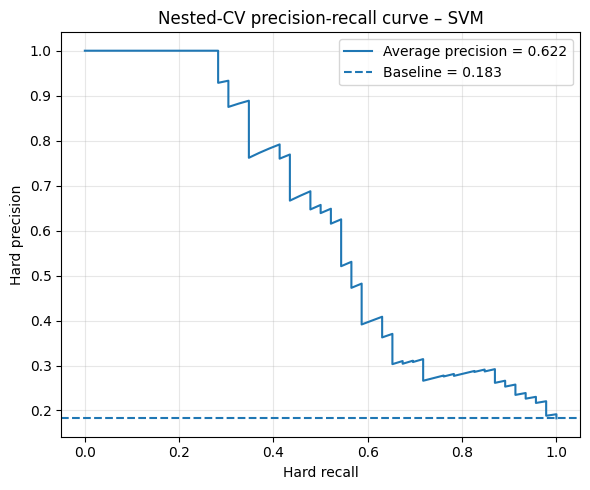


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.523
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.75, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.591
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.5, 'selector__k': 5, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 3
Best inner-CV F1 hard: 0.459
Best parameters: {'classifier__n_neighbors': 7, 'classifier__p': 2, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.75, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.547
Best parameters: {'classifier__n_neigh

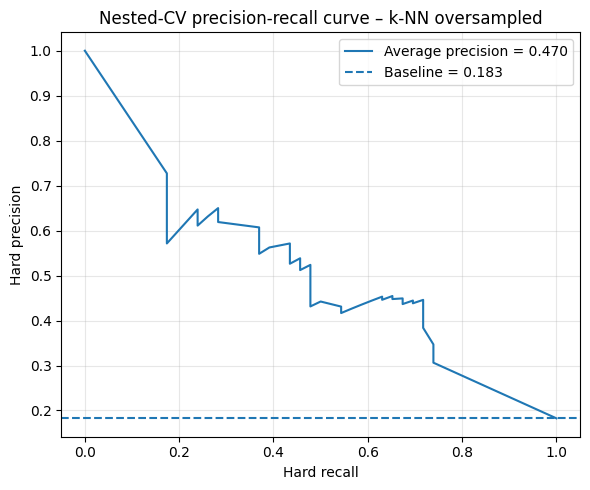


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.497
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': None, 'classifier__min_samples_leaf': 5, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.532
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.495
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 4
Best inner-CV F1 hard: 0.552
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classif

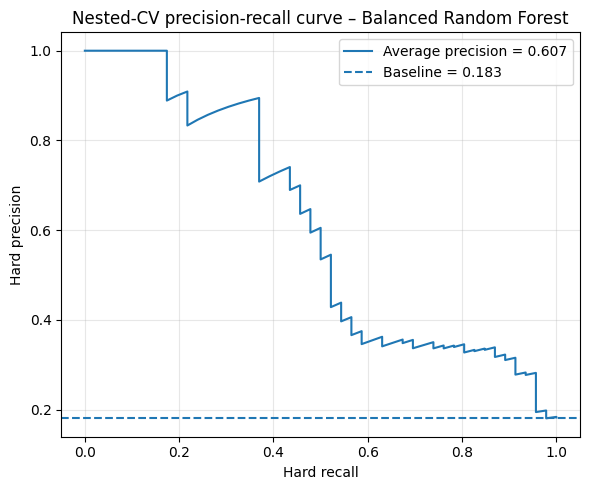


NESTED CROSS-VALIDATION SUMMARY
                   dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180424_M1                    SVM                0.732513               0.139040             0.653333             0.23196          0.527778         0.247394      0.575397     0.227734               0.937248              0.046036
spike_features_20180424_M1       k-NN oversampled                0.684555               0.102795             0.530952             0.20852          0.480556         0.176493      0.494069     0.169071               0.888555              0.079514
spike_features_20180424_M1 Balanced Random Forest                0.689210               0.110760             0.443297             0.19165          0.567778         0.259998      0.460529     0.129607               0.810642          

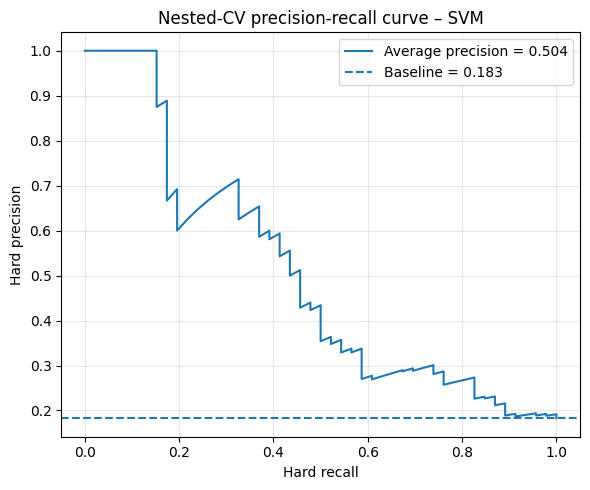


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.561
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 2, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.25, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.554
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 1, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.25, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.475
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.5, 'selector__k': 5, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 4
Best inner-CV F1 hard: 0.540
Best parameters: {'classifier__n_neig

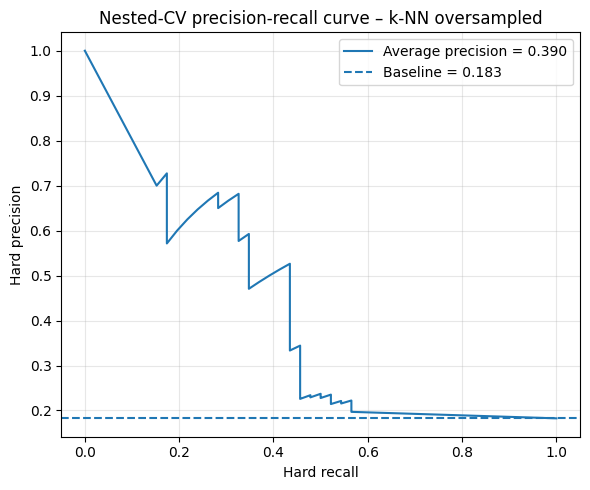


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.588
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.545
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 3
Best inner-CV F1 hard: 0.497
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 4
Best inner-CV F1 hard: 0.515
Best

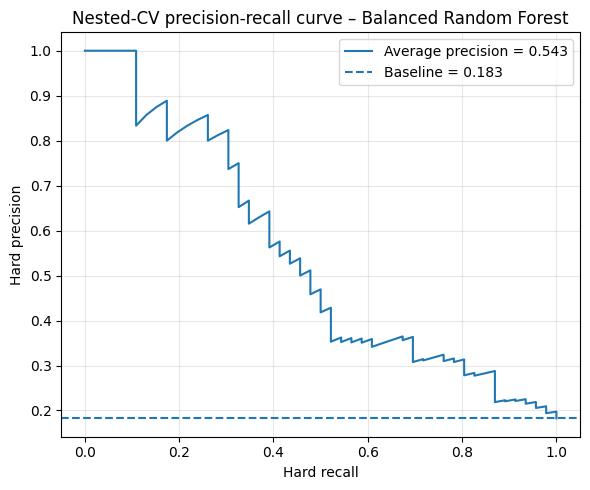


NESTED CROSS-VALIDATION SUMMARY
                              dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180424_M1_Chattering                    SVM                0.669873               0.108301             0.625152            0.300095          0.433333         0.307419      0.443542     0.192704               0.906412              0.132024
spike_features_20180424_M1_Chattering       k-NN oversampled                0.640917               0.106729             0.400952            0.246895          0.368889         0.232989      0.383942     0.239041               0.912946              0.042980
spike_features_20180424_M1_Chattering Balanced Random Forest                0.672750               0.099962             0.437770            0.191901          0.525556         0.234573      0.443115  

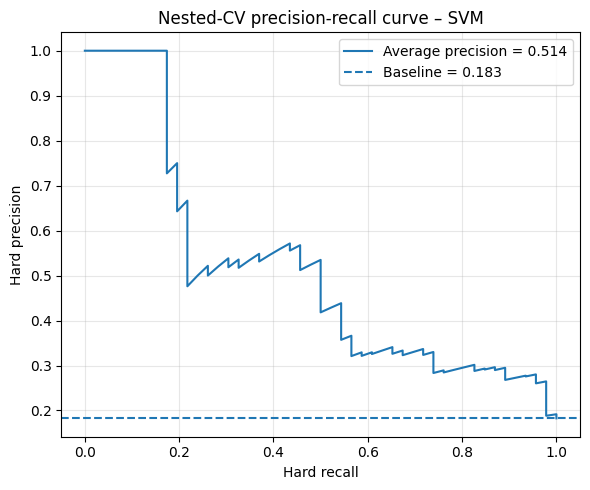


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.544
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.25, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.566
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.75, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.554
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.75, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.596
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 1, 'classifier__weights': 'distance', 'sampler__sam

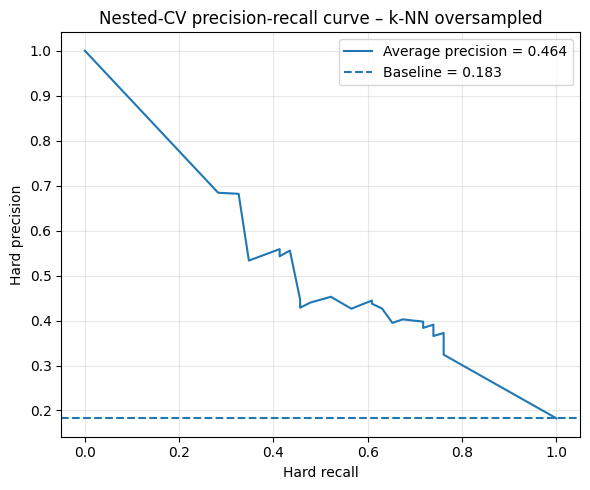


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.532
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': None, 'classifier__min_samples_leaf': 3, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.517
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.503
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.557
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 'all', 'selector__score_func': <function f_cl

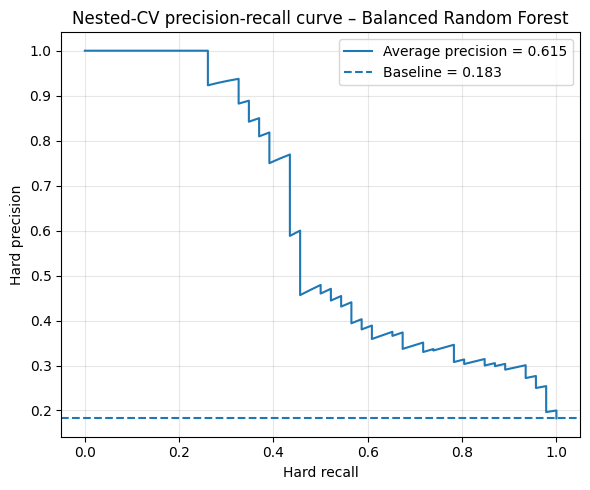


NESTED CROSS-VALIDATION SUMMARY
                               dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180424_M1_FastSpiking                    SVM                0.696269               0.121410             0.585714            0.233649          0.505556         0.340071      0.448986     0.186990               0.886982              0.101054
spike_features_20180424_M1_FastSpiking       k-NN oversampled                0.710369               0.106246             0.472500            0.129623          0.590556         0.259745      0.483644     0.127915               0.830183              0.088742
spike_features_20180424_M1_FastSpiking Balanced Random Forest                0.689044               0.089289             0.388009            0.058136          0.587778         0.237086      0.4537

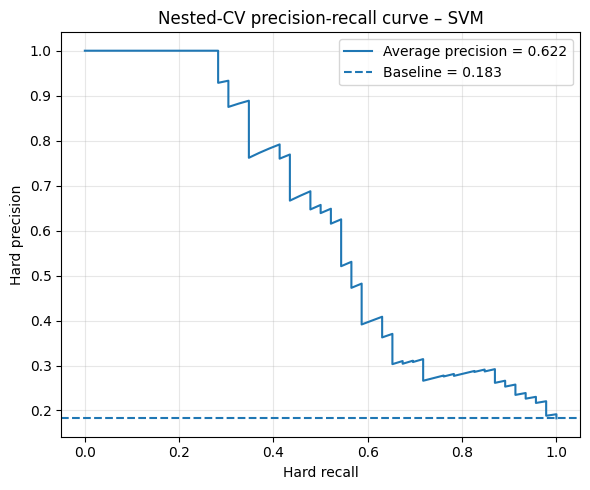


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.523
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.75, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.591
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.5, 'selector__k': 5, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 3
Best inner-CV F1 hard: 0.459
Best parameters: {'classifier__n_neighbors': 7, 'classifier__p': 2, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.75, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.547
Best parameters: {'classifier__n_neigh

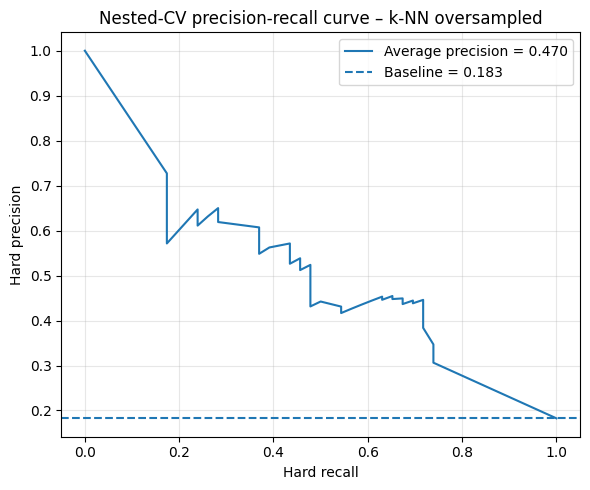


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.497
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': None, 'classifier__min_samples_leaf': 5, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.532
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.495
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 4
Best inner-CV F1 hard: 0.552
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classif

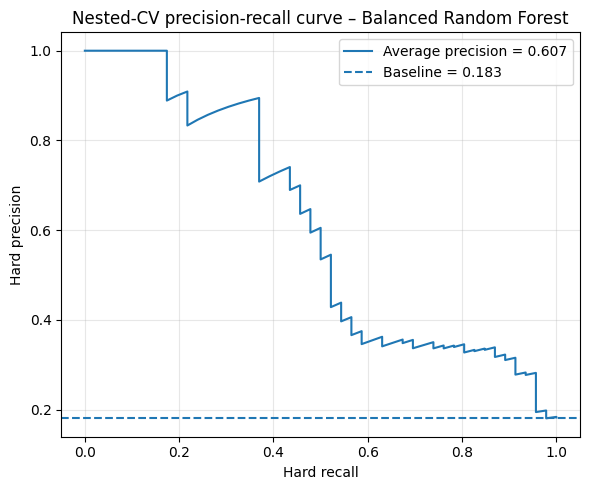


NESTED CROSS-VALIDATION SUMMARY
                                  dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180424_M1_RegularSpiking                    SVM                0.732513               0.139040             0.653333             0.23196          0.527778         0.247394      0.575397     0.227734               0.937248              0.046036
spike_features_20180424_M1_RegularSpiking       k-NN oversampled                0.684555               0.102795             0.530952             0.20852          0.480556         0.176493      0.494069     0.169071               0.888555              0.079514
spike_features_20180424_M1_RegularSpiking Balanced Random Forest                0.689210               0.110760             0.443297             0.19165          0.567778         0.259998

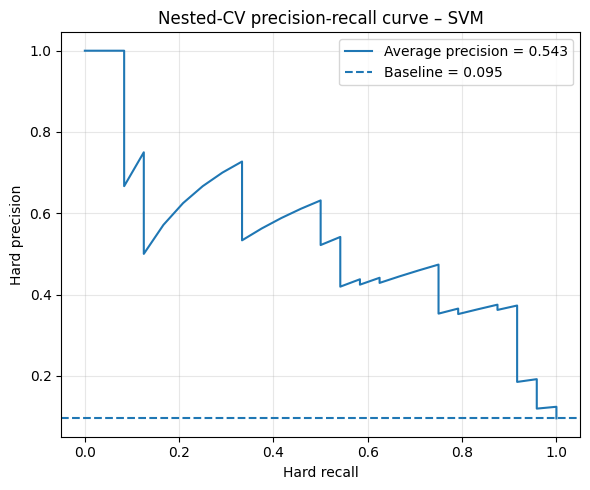


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.718
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.5, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.673
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.25, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.667
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.25, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.718
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampli

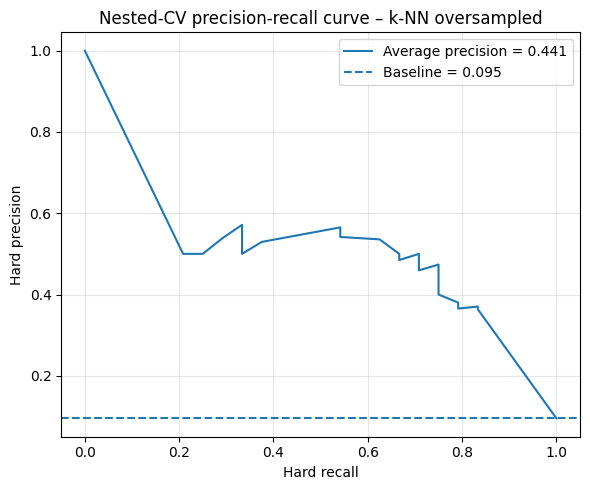


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.599
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.632
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.595
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.599
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72

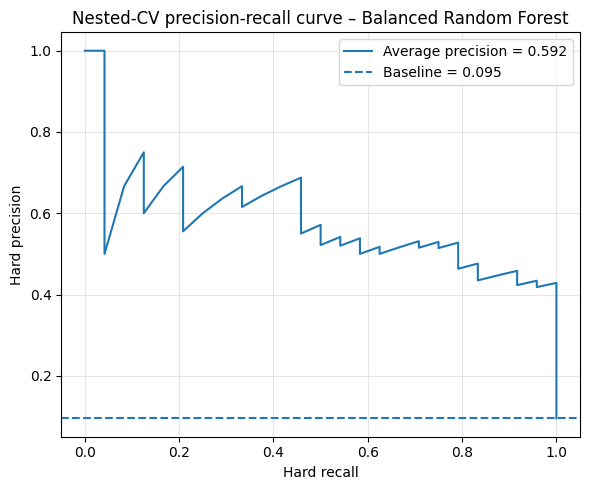


NESTED CROSS-VALIDATION SUMMARY
                   dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180427_M1                    SVM                0.812054               0.147367             0.460000            0.217498          0.720000         0.313449      0.537733     0.205903               0.904108              0.048833
spike_features_20180427_M1       k-NN oversampled                0.796215               0.129596             0.490476            0.161627          0.666667         0.246080      0.556781     0.189049               0.925763              0.031981
spike_features_20180427_M1 Balanced Random Forest                0.929878               0.011985             0.430303            0.077702          1.000000         0.000000      0.598333     0.077370               0.859756          

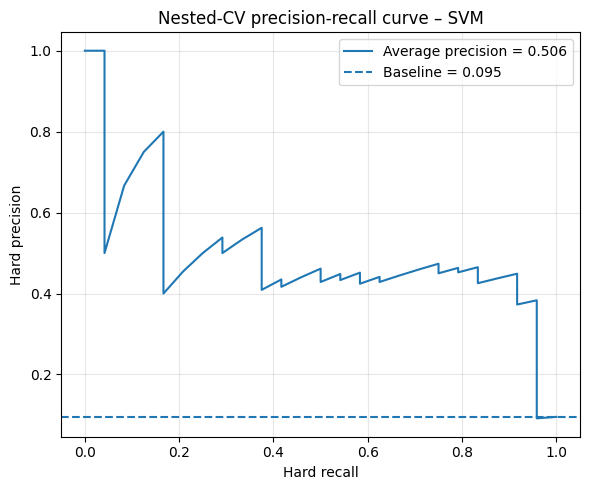


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.748
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.25, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.722
Best parameters: {'classifier__n_neighbors': 7, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.25, 'selector__k': 5, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 3
Best inner-CV F1 hard: 0.631
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 2, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.5, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.725
Best parameters: {'classifier__n_ne

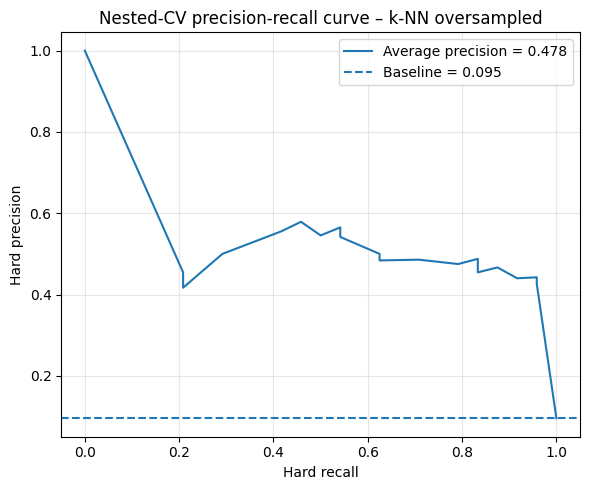


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.628
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.648
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.595
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.609
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72

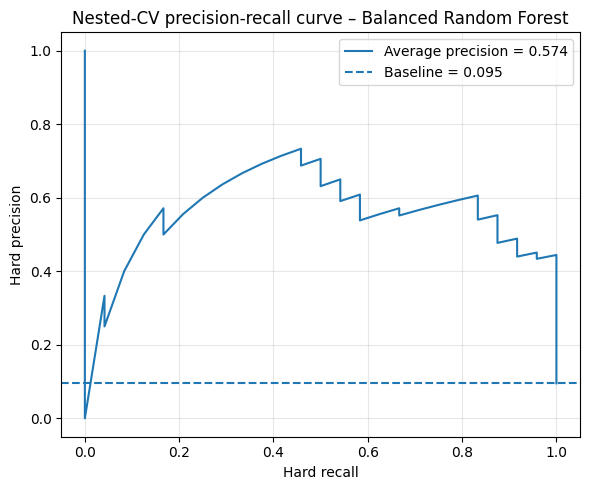


NESTED CROSS-VALIDATION SUMMARY
                              dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180427_M1_Chattering                    SVM                0.869550               0.168829             0.441111            0.139863          0.840000         0.357771      0.565873     0.208618               0.899101              0.028995
spike_features_20180427_M1_Chattering       k-NN oversampled                0.852658               0.074358             0.500952            0.136130          0.796667         0.144530      0.602429     0.118298               0.908650              0.049850
spike_features_20180427_M1_Chattering Balanced Random Forest                0.934325               0.012623             0.446667            0.083198          1.000000         0.000000      0.613796  

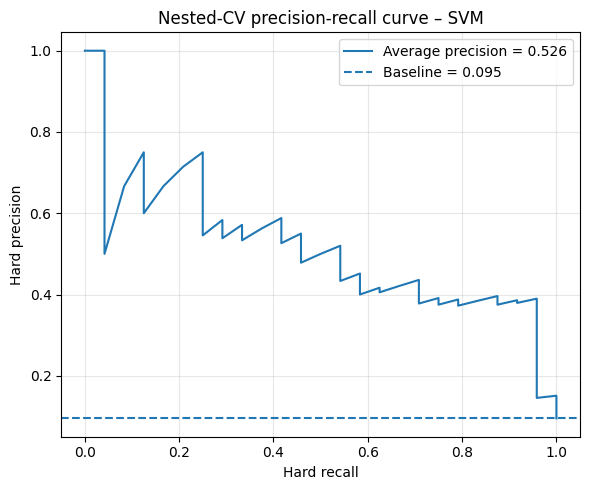


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.705
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.5, 'selector__k': 5, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 2
Best inner-CV F1 hard: 0.717
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 1.0, 'selector__k': 3, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 3
Best inner-CV F1 hard: 0.666
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.25, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>

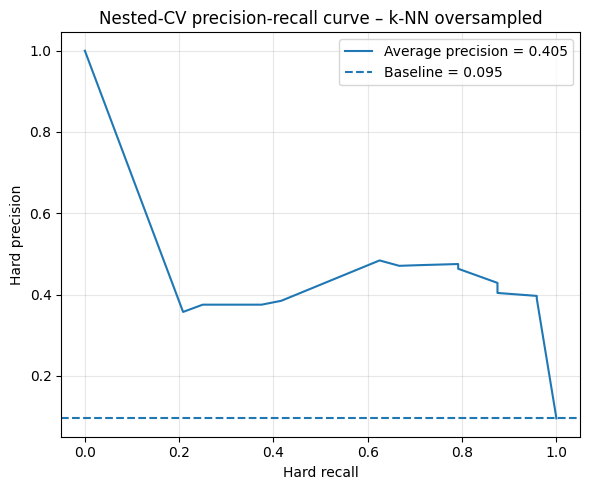


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.582
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.642
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 3
Best inner-CV F1 hard: 0.589
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 4
Best inner-CV F1 hard: 0.641
Best parameter

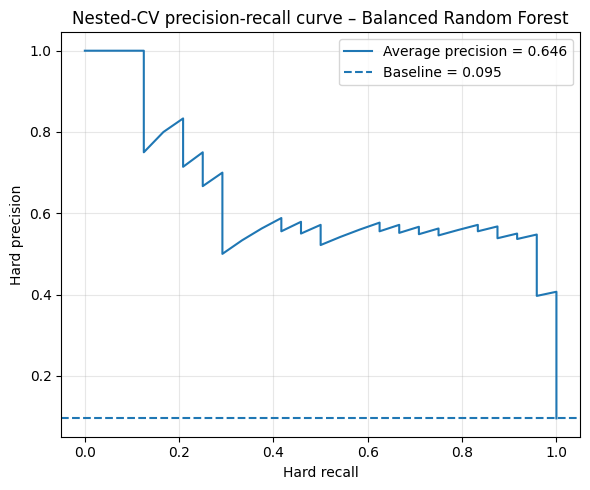


NESTED CROSS-VALIDATION SUMMARY
                               dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180427_M1_FastSpiking                    SVM                0.743900               0.070785             0.404762            0.123718          0.580000         0.130384      0.471775     0.119887               0.907801              0.029040
spike_features_20180427_M1_FastSpiking       k-NN oversampled                0.812061               0.078630             0.530736            0.187500          0.706667         0.175040      0.573846     0.145007               0.917454              0.065047
spike_features_20180427_M1_FastSpiking Balanced Random Forest                0.915541               0.030631             0.450830            0.143514          0.966667         0.074536      0.5996

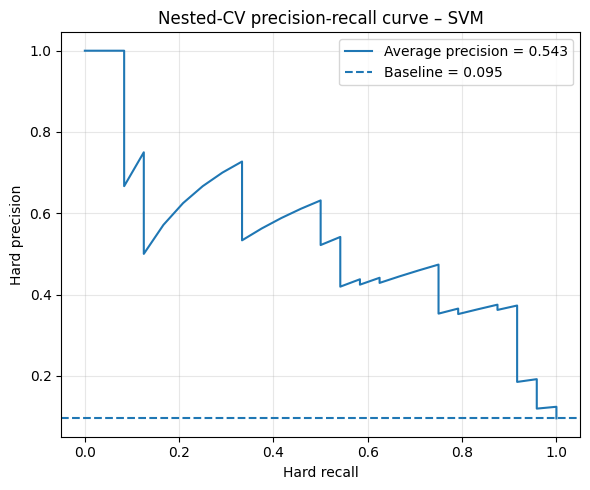


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.718
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.5, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.673
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 1, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.25, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.667
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.25, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.718
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampli

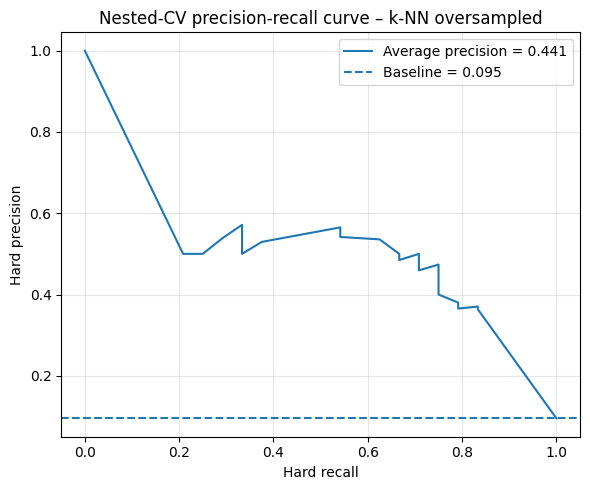


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.599
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.632
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.595
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.599
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72

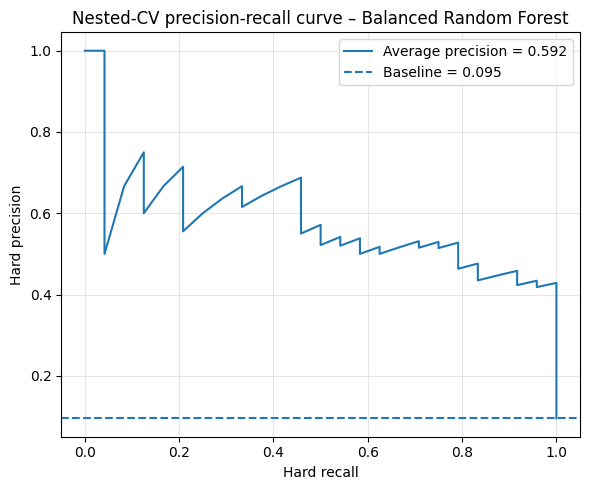


NESTED CROSS-VALIDATION SUMMARY
                                  dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180427_M1_RegularSpiking                    SVM                0.812054               0.147367             0.460000            0.217498          0.720000         0.313449      0.537733     0.205903               0.904108              0.048833
spike_features_20180427_M1_RegularSpiking       k-NN oversampled                0.796215               0.129596             0.490476            0.161627          0.666667         0.246080      0.556781     0.189049               0.925763              0.031981
spike_features_20180427_M1_RegularSpiking Balanced Random Forest                0.929878               0.011985             0.430303            0.077702          1.000000         0.000000

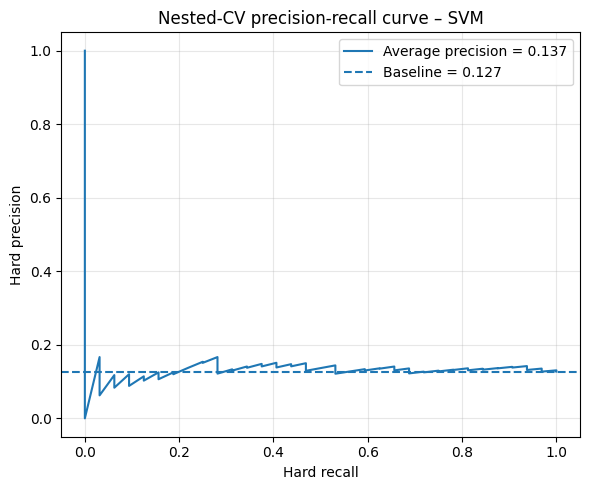


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.238
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.5, 'selector__k': 3, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 2
Best inner-CV F1 hard: 0.317
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.25, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.336
Best parameters: {'classifier__n_neighbors': 7, 'classifier__p': 1, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.5, 'selector__k': 3, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbor

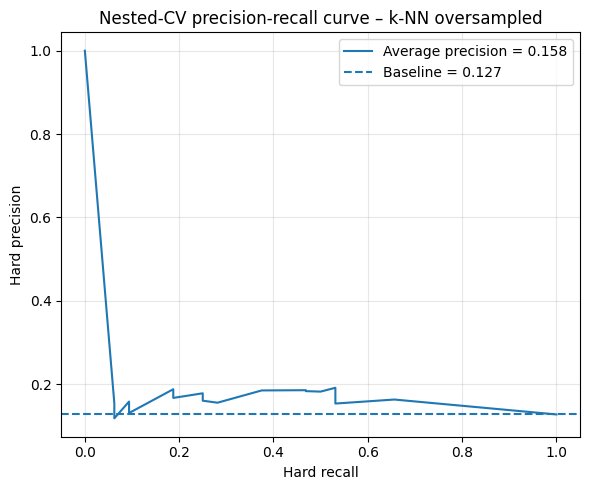


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.205
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.302
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.287
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.364
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': None, 'classifier__min_samples_leaf': 3, 'selector__k': 3, 'selector__score_func': functools.partial(<funct

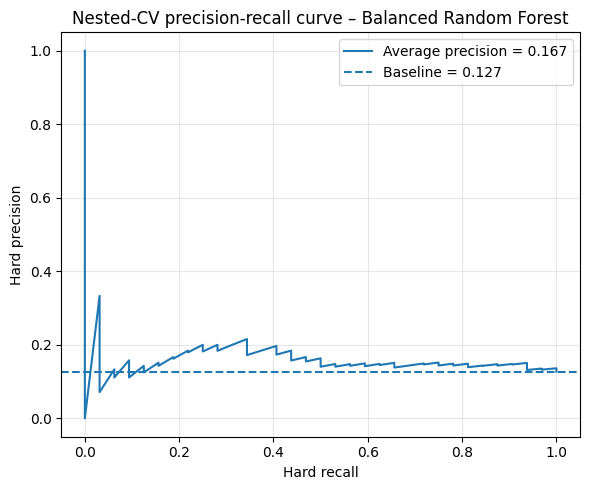


NESTED CROSS-VALIDATION SUMMARY
                   dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180518_M2                    SVM                0.532987               0.122336             0.141351            0.073019          0.457143         0.256105      0.215453     0.114057               0.608831              0.057784
spike_features_20180518_M2       k-NN oversampled                0.524214               0.094539             0.113205            0.126491          0.238095         0.242810      0.152878     0.165581               0.810332              0.121349
spike_features_20180518_M2 Balanced Random Forest                0.562338               0.078800             0.167264            0.062170          0.428571         0.175772      0.240082     0.091848               0.696104          

Best inner-CV F1 hard: 0.305
Best parameters: {'classifier__C': 30, 'classifier__class_weight': 'balanced', 'classifier__kernel': 'linear', 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}


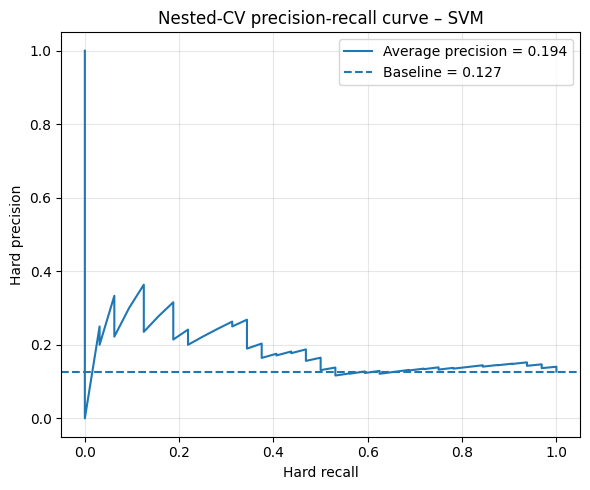


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.292
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 2, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 1.0, 'selector__k': 3, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 2
Best inner-CV F1 hard: 0.385
Best parameters: {'classifier__n_neighbors': 7, 'classifier__p': 2, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.5, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.409
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 1, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.5, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.367
Best parameters: {'classifier__n_ne

Best inner-CV F1 hard: 0.344
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 1, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.5, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}


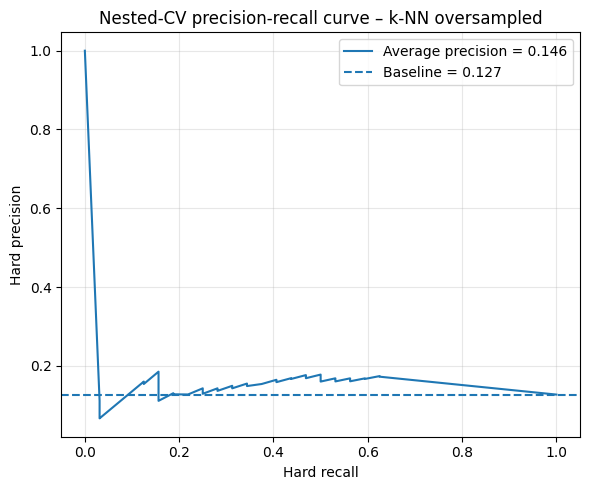


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.230
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 3, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.354
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.414
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.290
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': functools

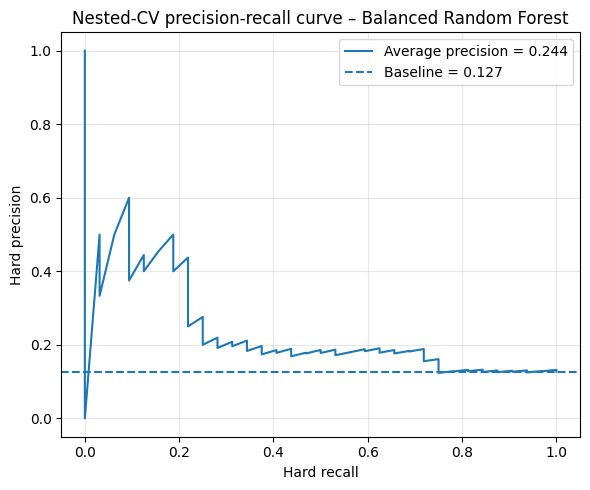


NESTED CROSS-VALIDATION SUMMARY
                              dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180518_M2_Chattering                    SVM                0.545541               0.089318             0.144679            0.052749          0.495238         0.254995      0.221845     0.085529               0.595844              0.091586
spike_features_20180518_M2_Chattering       k-NN oversampled                0.518470               0.104890             0.132857            0.099693          0.285714         0.249716      0.175824     0.129507               0.751227              0.087784
spike_features_20180518_M2_Chattering Balanced Random Forest                0.577994               0.074928             0.177978            0.053966          0.433333         0.196627      0.250143  

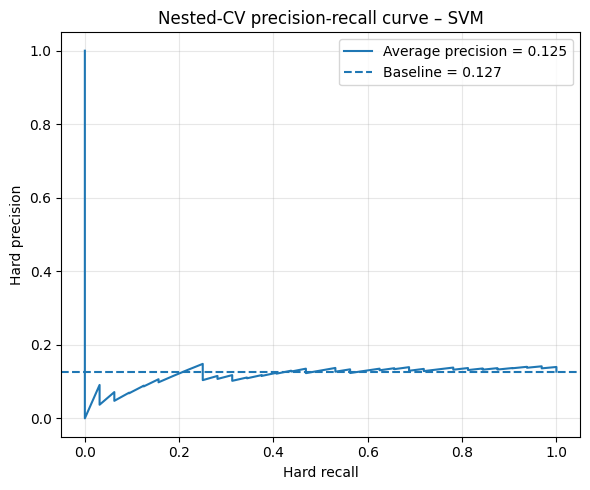


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.384
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.5, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.348
Best parameters: {'classifier__n_neighbors': 5, 'classifier__p': 2, 'classifier__weights': 'distance', 'sampler__sampling_strategy': 0.25, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.455
Best parameters: {'classifier__n_neighbors': 3, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.75, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.456
Best parameters: {'classifier__n_neighbors': 7, 'classifier__p': 2, 'classifier__weights': 'distance', 'sampler__

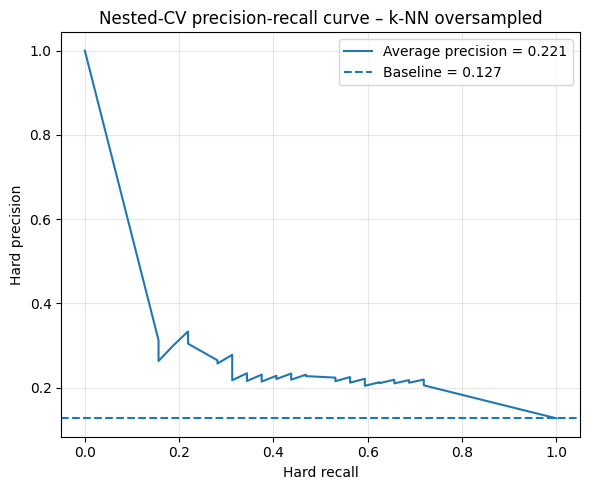


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.273
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 5, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.332
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.310
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.330
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': functools.pa

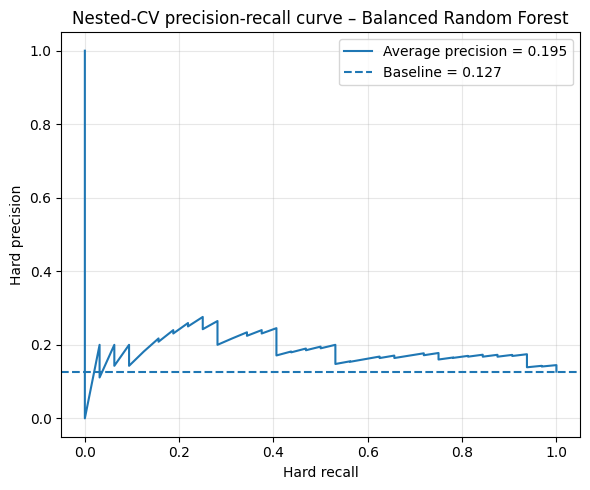


NESTED CROSS-VALIDATION SUMMARY
                               dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180518_M2_FastSpiking                    SVM                0.506075               0.090609             0.125722            0.046104          0.500000         0.241053      0.198923     0.075513               0.512150              0.127358
spike_features_20180518_M2_FastSpiking       k-NN oversampled                0.575253               0.073632             0.246032            0.101637          0.304762         0.166156      0.256074     0.099812               0.845743              0.081242
spike_features_20180518_M2_FastSpiking Balanced Random Forest                0.590491               0.102415             0.199739            0.086510          0.471429         0.160074      0.2771

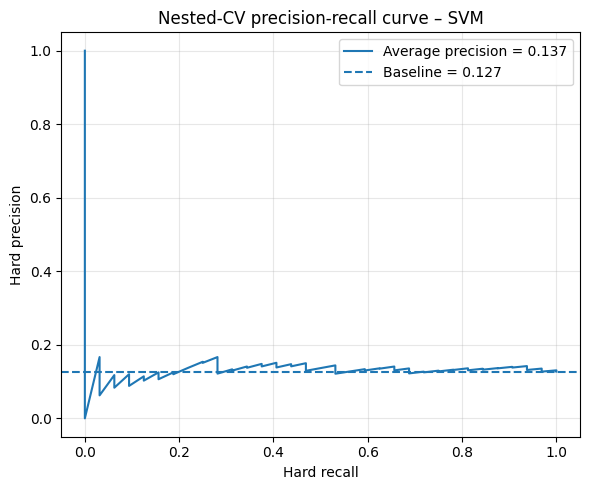


NESTED CROSS-VALIDATION: k-NN oversampled

Outer fold 1
Best inner-CV F1 hard: 0.238
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.5, 'selector__k': 3, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbors=3)}

Outer fold 2
Best inner-CV F1 hard: 0.317
Best parameters: {'classifier__n_neighbors': 9, 'classifier__p': 2, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.25, 'selector__k': 'all', 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.336
Best parameters: {'classifier__n_neighbors': 7, 'classifier__p': 1, 'classifier__weights': 'uniform', 'sampler__sampling_strategy': 0.5, 'selector__k': 3, 'selector__score_func': functools.partial(<function mutual_info_classif at 0x72feb5ed60c0>, discrete_features=False, random_state=42, n_neighbor

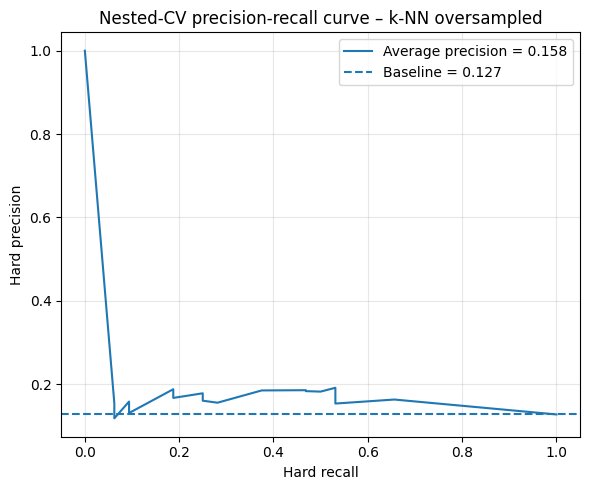


NESTED CROSS-VALIDATION: Balanced Random Forest

Outer fold 1
Best inner-CV F1 hard: 0.205
Best parameters: {'classifier__max_depth': 3, 'classifier__max_features': None, 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 2
Best inner-CV F1 hard: 0.302
Best parameters: {'classifier__max_depth': None, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 5, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 3
Best inner-CV F1 hard: 0.287
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': 'sqrt', 'classifier__min_samples_leaf': 2, 'selector__k': 3, 'selector__score_func': <function f_classif at 0x72feb5b1c5e0>}

Outer fold 4
Best inner-CV F1 hard: 0.364
Best parameters: {'classifier__max_depth': 4, 'classifier__max_features': None, 'classifier__min_samples_leaf': 3, 'selector__k': 3, 'selector__score_func': functools.partial(<funct

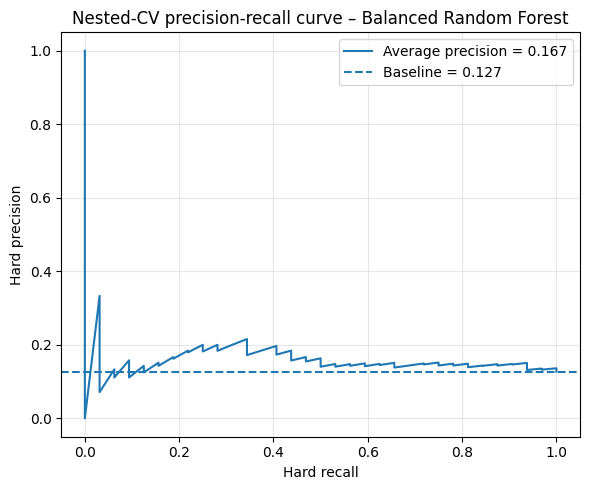


NESTED CROSS-VALIDATION SUMMARY
                                  dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
spike_features_20180518_M2_RegularSpiking                    SVM                0.532987               0.122336             0.141351            0.073019          0.457143         0.256105      0.215453     0.114057               0.608831              0.057784
spike_features_20180518_M2_RegularSpiking       k-NN oversampled                0.524214               0.094539             0.113205            0.126491          0.238095         0.242810      0.152878     0.165581               0.810332              0.121349
spike_features_20180518_M2_RegularSpiking Balanced Random Forest                0.562338               0.078800             0.167264            0.062170          0.428571         0.175772

In [10]:
# ====================================================================
# CLASSIFY ALL DATASETS
# ====================================================================

all_dataset_summaries = []
failed_datasets = []

for file_index, csv_file in enumerate(
    csv_files,
    start=1
):

    print("\n")
    print("#" * 80)

    print(
        f"PROCESSING {file_index}/{len(csv_files)}: "
        f"{csv_file.name}"
    )

    print("#" * 80)

    try:

        current_summary = (
            runClassificationForOneFile(
                csv_path=csv_file,
                results_root=results_root
            )
        )

        all_dataset_summaries.append(
            current_summary
        )

    except Exception as error:

        print(
            f"Error processing {csv_file.name}: "
            f"{error}"
        )

        failed_datasets.append({
            "file": csv_file.name,
            "error": str(error)
        })

## 9. Global Results Summary

This final section combines the classification summaries obtained from all successfully processed datasets.

The resulting table contains one row for each dataset–classifier combination. 

The combined results are saved as all_datasets_summary.csv, allowing a direct comparison of classifier performance across acquisitions.

Datasets that could not be processed are stored separately in failed_datasets.csv, together with their error messages.

In [ ]:
# ====================================================================
# SAVE GLOBAL SUMMARY
# ====================================================================
if len(all_dataset_summaries) > 0:

    global_summary = pd.concat(
        all_dataset_summaries,
        ignore_index=True
    )

    global_summary.to_csv(
        results_root
        / "all_datasets_summary.csv",
        sep=";",
        index=False
    )

    print("\nGLOBAL SUMMARY")

    print(
        global_summary.to_string(
            index=False
        )
    )


if len(failed_datasets) > 0:

    failed_table = pd.DataFrame(
        failed_datasets
    )

    failed_table.to_csv(
        results_root
        / "failed_datasets.csv",
        sep=";",
        index=False
    )

    print("\nFAILED DATASETS")

    print(
        failed_table.to_string(
            index=False
        )
    )



GLOBAL SUMMARY
                                  dataset                  model  balanced_accuracy_mean  balanced_accuracy_std  precision_hard_mean  precision_hard_std  recall_hard_mean  recall_hard_std  f1_hard_mean  f1_hard_std  specificity_soft_mean  specificity_soft_std
               spike_features_20180424_M1                    SVM                0.732513               0.139040             0.653333            0.231960          0.527778         0.247394      0.575397     0.227734               0.937248              0.046036
               spike_features_20180424_M1       k-NN oversampled                0.684555               0.102795             0.530952            0.208520          0.480556         0.176493      0.494069     0.169071               0.888555              0.079514
               spike_features_20180424_M1 Balanced Random Forest                0.689210               0.110760             0.443297            0.191650          0.567778         0.259998      0.460529   

## 10. Cross-Phantom Comparison (FastSpiking, Balanced Random Forest)

This section compares the decoding performance across the three phantoms, ordered by
decreasing inclusion–matrix contrast (27/04 > 24/04 > 18/05), using the best performing neuron type
(**FastSpiking**) and classifier (**Balanced Random Forest**).

The goal is to show that the performance drop follows the physical contrast of each phantom:
a monotonic decrease supports the interpretation that the low performance of the 18/05 phantom
is explained by its design (weak inclusion–matrix contrast) rather than by a failure of the
decoding method. This is consistent with the data processing inequality: the decoder can recover
only as much information about the stimulus as the contrast injected into the force signal.

Two robust metrics are shown side by side, with error bars given by the standard deviation across
the outer folds: **balanced accuracy** (equal weight to the hard and soft classes) and the
**F1 score of the hard class** (the minority class of interest).

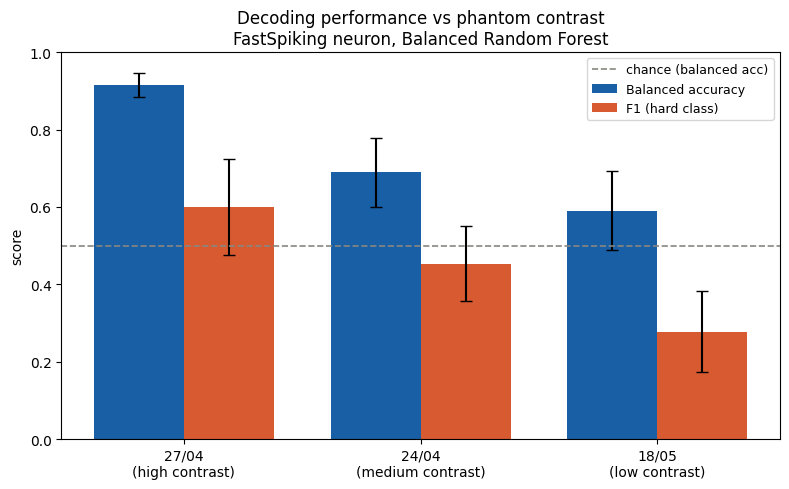

In [16]:
# ====================================================================
# 10. CROSS-PHANTOM COMPARISON PLOT
#     FastSpiking neuron, Balanced Random Forest classifier
# ====================================================================

# 1. Source table: use the in-memory global_summary if available,
#    otherwise reload it from the saved CSV.
if "global_summary" in globals():
    summary_df = global_summary.copy()
else:
    summary_df = pd.read_csv(
        results_root / "all_datasets_summary.csv",
        sep=";"
    )


# 2. The three FastSpiking datasets, mapped to a readable phantom label
#    and ordered by DECREASING inclusion-matrix contrast.
phantom_datasets = [
    ("spike_features_20180427_M1_FastSpiking", "27/04\n(high contrast)"),
    ("spike_features_20180424_M1_FastSpiking", "24/04\n(medium contrast)"),
    ("spike_features_20180518_M2_FastSpiking", "18/05\n(low contrast)"),
]

model_name = "Balanced Random Forest"


# 3. Collect the metrics for each phantom, keeping the contrast order.
plot_rows = []

for dataset_name, phantom_label in phantom_datasets:

    row = summary_df[
        (summary_df["dataset"] == dataset_name)
        & (summary_df["model"] == model_name)
    ]

    if row.empty:
        print(f"WARNING: no row found for {dataset_name} / {model_name}")
        continue

    row = row.iloc[0]

    plot_rows.append({
        "phantom": phantom_label,
        "bal_acc_mean": row["balanced_accuracy_mean"],
        "bal_acc_std": row["balanced_accuracy_std"],
        "f1_mean": row["f1_hard_mean"],
        "f1_std": row["f1_hard_std"],
    })

plot_df = pd.DataFrame(plot_rows)


# 4. Grouped bar chart: balanced accuracy and F1-hard, with fold-wise error bars.
positions = np.arange(len(plot_df))
bar_width = 0.38

fig, ax = plt.subplots(figsize=(8, 5))

ax.bar(
    positions - bar_width / 2,
    plot_df["bal_acc_mean"],
    yerr=plot_df["bal_acc_std"],
    width=bar_width,
    color="#185FA5",
    capsize=4,
    label="Balanced accuracy"
)

ax.bar(
    positions + bar_width / 2,
    plot_df["f1_mean"],
    yerr=plot_df["f1_std"],
    width=bar_width,
    color="#D85A30",
    capsize=4,
    label="F1 (hard class)"
)

# Chance level for balanced accuracy in a binary problem
ax.axhline(
    0.5,
    color="#888780",
    linestyle="--",
    linewidth=1.2,
    label="chance (balanced acc)"
)

ax.set_xticks(positions)
ax.set_xticklabels(plot_df["phantom"])
ax.set_ylabel("score")
ax.set_ylim(0, 1)
ax.set_title(
    "Decoding performance vs phantom contrast\n"
    "FastSpiking neuron, Balanced Random Forest"
)
ax.legend(loc="upper right", fontsize=9)

fig.tight_layout()

# 5. Save the figure next to the other results.
fig.savefig(
    results_root / "cross_phantom_fastspiking_brf.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()